# Tarea 3 — Aprendizaje supervisado: priorización de posibles falsas alarmas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

In [2]:
url = "https://raw.githubusercontent.com/ElenaVillano/databases/refs/heads/main/db_falsas_alarmas.csv"
df = pd.read_csv(url)


## Parte A: aprendizaje supervisado

### A1. Formulación y modelo inicial

In [3]:
df.head()

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud
0,C5/20220923/04016,2022-09-23 18:38:34,2022-09-23 22:22:27,Accidente,Choque sin lesionados,VENUSTIANO CARRANZA,A,EMERGENCIA,LLAMADA DEL 911,VENUSTIANO CARRANZA,Venustiano Carranza,20 De Noviembre,-99.108352,19.443920
1,C5/20220829/00630,2022-08-29 02:56:31,2022-08-29 06:04:53,Accidente,Motociclista,CUAUHTEMOC,A,URGENCIAS MEDICAS,LLAMADA DEL 911,CUAUHTEMOC,Cuauhtémoc,Obrera,-99.140843,19.416669
2,C5/20220724/01907,2022-07-24 04:29:09,2022-07-24 07:36:49,Accidente,Choque sin lesionados,IZTAPALAPA,A,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,San Andres Tetepilco,-99.130702,19.371340
3,C5/20240215/03071,2024-02-15 16:20:03,2024-02-15 20:52:19,Accidente,Choque sin lesionados,LA MAGDALENA CONTRERAS,A,EMERGENCIA,LLAMADA DEL 911,LA MAGDALENA CONTRERAS,La Magdalena Contreras,La Cruz,-99.233973,19.305985
4,C5/20221006/03493,2022-10-06 19:33:05,2022-10-06 22:37:08,Accidente,Choque sin lesionados,IZTAPALAPA,F,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,Santa Martha Acatitla Norte,-99.013140,19.374476


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 124261 entries, 0 to 124260
Data columns (total 14 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   folio                124261 non-null  str    
 1   fecha_hora_creacion  124261 non-null  str    
 2   fecha_hora_cierre    124261 non-null  str    
 3   tipo_incidente_c4    124261 non-null  str    
 4   incidente_c4         124261 non-null  str    
 5   alcaldia_inicio      124253 non-null  str    
 6   codigo_cierre        124261 non-null  str    
 7   clas_con_f_alarma    124261 non-null  str    
 8   tipo_entrada         124261 non-null  str    
 9   alcaldia_cierre      124253 non-null  str    
 10  alcaldia_catalogo    124131 non-null  str    
 11  colonia_catalogo     121543 non-null  str    
 12  longitud             124261 non-null  float64
 13  latitud              124261 non-null  float64
dtypes: float64(2), str(12)
memory usage: 13.3 MB


In [5]:
df["codigo_cierre"].value_counts()

codigo_cierre
D    52963
A    45189
F    25219
I      890
Name: count, dtype: int64

In [6]:
df["codigo_cierre"].value_counts(normalize=True)

codigo_cierre
D    0.426224
A    0.363662
F    0.202952
I    0.007162
Name: proportion, dtype: float64

|Código|Significado|
|----|----|
|A|Afirmativo: la unidad llegó y confirmó la emergencia.|
|N|Negativo: la unidad llegó, pero nadie confirmó la emergencia o solicitó apoyo.|
|I|Informativo: solicitud de información.|
|F|Falso: el incidente fue considerado falso en el lugar.|
|D|Duplicado: se registró el mismo incidente más de una vez.|

**Unidad de predicción**
:Cada fila representa una llamada o reporte individual, identificado mediante su folio.

**Momento de predicción**
:El score se calcularía cuando se crea la llamada, antes de conocer cómo terminará o qué código de cierre recibirá.

**Etiqueta**
:La etiqueta se construye a partir de codigo_cierre. La clase 1 corresponde a los reportes que cierran con F; la clase 0 corresponde a los que no cierran con F.

**Tratamiento de los códigos de cierre**
:A, D e I, son códigos distintos de F, por lo tanto quedan como 0.

**Tasa base**
:Es aproximadamente 20.3%, es decir, la proporción de reportes que cierran con F en la base, al conservar los demás códigos como clase 0.

| Feature | Tipo | Disponible al momento del reporte |
|---------|------|:-------------------------------:|
| `incidente_c4` | Categórica | Sí |
| `tipo_incidente_c4` | Categórica | Sí |
| `alcaldia_inicio` | Categórica | Sí |
| `tipo_entrada` | Categórica | Sí |
| `hora_del_dia` | Numérica | Sí |
| `dia_semana` | Numérica | Sí |

- Predictores disponibles al crear la llamada (leakage): fecha_hora_cierre, codigo_cierre, alcaldia_cierre, clas_con_f_alarma, cada una con su razón corta.
- Prdictores disponibles pero no usados en la inicial: folio (es un identificador), latitud, longitud, colonia_catalogo, alcaldia_catalogo.

Usaremos el modelo de dummy, esperando que al tener el mismo score, los 100 reportes seleccionados den una eficiecia aproximamda del 20.3%. Así mismo, esperamos un AUC de 0.5.

**Limpieza y Procesamiento**

Primero pasamos de texto a datetime para extraer la hora del día y el día de la semana como predictores. Los reportes se organizarán en los trimestres correspondientes a la validación temporal y en las semanas utilizadas para calcular las métricas. 

In [7]:
df['fecha_hora_creacion'] = pd.to_datetime(df['fecha_hora_creacion'])
df['fecha_hora_cierre'] = pd.to_datetime(df['fecha_hora_cierre'])

print(df['fecha_hora_creacion'].min(), df['fecha_hora_creacion'].max())

2021-12-31 20:59:59 2024-02-29 20:53:56


Creamos la etiqueta binaria según lo que el modelo aprende a predecir:1 = F; 0 = A, D e I.

In [8]:
df['y_falsa_alarma'] = (df['codigo_cierre'] == 'F').astype(int)

df['y_falsa_alarma'].mean()

np.float64(0.20295185134515253)

A partir de la fecha de creación, creamos "hora_del_dia" y "dia_semana", ya que el modelo no puede usar la fecha completa. Después definimos las variables del modelo inicial, para definir qué columnas usará el modelo y separalas por tipo en "columnas_categoricass" y columnas numericas", ya que las categóricas se convierten con one-hot y las numéricas se usan directamente.



In [9]:
#tiempo
df['hora_del_dia'] = df['fecha_hora_creacion'].dt.hour
df['dia_semana']   = df['fecha_hora_creacion'].dt.day_of_week  # 0=lunes, 6=domingo

# modelo inicial
columnas_categoricas = ['incidente_c4', 'tipo_incidente_c4', 'alcaldia_inicio', 'tipo_entrada']
columnas_numericas   = ['hora_del_dia', 'dia_semana']


In [10]:
print('Valores faltantes por columna:')
print(df.isnull().sum())

Valores faltantes por columna:
folio                     0
fecha_hora_creacion       0
fecha_hora_cierre         0
tipo_incidente_c4         0
incidente_c4              0
alcaldia_inicio           8
codigo_cierre             0
clas_con_f_alarma         0
tipo_entrada              0
alcaldia_cierre           8
alcaldia_catalogo       130
colonia_catalogo       2718
longitud                  0
latitud                   0
y_falsa_alarma            0
hora_del_dia              0
dia_semana                0
dtype: int64


In [11]:
df = df.dropna(subset=['alcaldia_inicio','colonia_catalogo'])
print(f'Registros después de limpiar nulos: {len(df):,}')

Registros después de limpiar nulos: 121,540


In [12]:
print('Valores faltantes por columna:')
print(df.isnull().sum())

Valores faltantes por columna:
folio                   0
fecha_hora_creacion     0
fecha_hora_cierre       0
tipo_incidente_c4       0
incidente_c4            0
alcaldia_inicio         0
codigo_cierre           0
clas_con_f_alarma       0
tipo_entrada            0
alcaldia_cierre         0
alcaldia_catalogo      60
colonia_catalogo        0
longitud                0
latitud                 0
y_falsa_alarma          0
hora_del_dia            0
dia_semana              0
dtype: int64


In [13]:

# Ordenamos por fecha
df_sorted = df.sort_values('fecha_hora_creacion').copy()

# Definimos los 4 splits temporales
splits_temporales = [
    {'nombre': 'Split 1 (test: 1er tri 2023)',
     'train_hasta': '2023-01-01',
     'test_desde':  '2023-01-01',
     'test_hasta':  '2023-04-01'},
    {'nombre': 'Split 2 (test: 2do tri 2023)',
     'train_hasta': '2023-04-01',
     'test_desde':  '2023-04-01',
     'test_hasta':  '2023-07-01'},
    {'nombre': 'Split 3 (test: 3er tri 2023)',
     'train_hasta': '2023-07-01',
     'test_desde':  '2023-07-01',
     'test_hasta':  '2023-10-01'},
    {'nombre': 'Split 4 (test: 4to tri 2023)',
     'train_hasta': '2023-10-01',
     'test_desde':  '2023-10-01',
     'test_hasta':  '2024-01-01'},
]

print('Tamaños de cada split:')

for s in splits_temporales:
    train = df_sorted[
        df_sorted['fecha_hora_creacion'] < s['train_hasta']
    ]

    test = df_sorted[
        (df_sorted['fecha_hora_creacion'] >= s['test_desde']) &
        (df_sorted['fecha_hora_creacion'] < s['test_hasta'])
    ]

    print(f"{s['nombre']}: train={len(train):,}, test={len(test):,}")



Tamaños de cada split:
Split 1 (test: 1er tri 2023): train=56,640, test=13,063
Split 2 (test: 2do tri 2023): train=69,703, test=13,349
Split 3 (test: 3er tri 2023): train=83,052, test=14,283
Split 4 (test: 4to tri 2023): train=97,335, test=15,382


**Modelos iniciales con validación temporal**

Usamos cuatro modelos de clasificación: Dummy Classifier, Árbol de Decisión, Regresión Logística y Random Forest. El modelo Dummy sirve como referencia, mientras que los otros tres se emplean para predecir si un reporte será una falsa alarma.

En cada periodo, entrenamos los modelos con los datos disponibles antes del trimestre de prueba y los evaluamos con los reportes de ese trimestre.

Respecto al notebook de clase, hicimos algunos cambios. Ajustamos los intervalos temporales para incluir correctamente todos los registros de cada trimestre. Además, aplicamos el One Hot Encoding por separado en cada periodo: primero lo aprendimos con los datos de entrenamiento y después lo aplicamos a los datos de prueba.

Finalmente, guardamos la predicción de cada reporte junto con el periodo, el modelo, la fecha, la etiqueta real y el score de falsa alarma. Esto nos permite calcular las métricas trimestrales y semanales.

In [14]:
modelos_temporales = {
    'Línea base (Dummy)':  DummyClassifier(strategy='most_frequent', random_state=42),
    'Árbol de Decisión':   DecisionTreeClassifier(max_depth=5, random_state=42),
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
}

scores_inicial = []   # guardamos un registro por reporte de prueba

for s in splits_temporales:
    mask_train = df_sorted['fecha_hora_creacion'] < s['test_desde']
    mask_test  = ((df_sorted['fecha_hora_creacion'] >= s['test_desde']) &
                  (df_sorted['fecha_hora_creacion'] <  s['test_hasta']))
    df_tr = df_sorted[mask_train]
    df_te = df_sorted[mask_test]

    # One-hot aprendido SOLO con train
    X_tr_cat = pd.get_dummies(df_tr[columnas_categoricas], drop_first=True)
    X_te_cat = pd.get_dummies(df_te[columnas_categoricas], drop_first=False).reindex(
        columns=X_tr_cat.columns, fill_value=0
    )

    X_tr = pd.concat([X_tr_cat, df_tr[columnas_numericas]], axis=1)
    X_te = pd.concat([X_te_cat, df_te[columnas_numericas]], axis=1)
    y_tr = df_tr['y_falsa_alarma']
    y_te = df_te['y_falsa_alarma']

    # Escalado 
    scaler_t    = StandardScaler()
    X_tr_scaled = scaler_t.fit_transform(X_tr)
    X_te_scaled = scaler_t.transform(X_te)

    for nombre, modelo in modelos_temporales.items():
        if nombre == 'Regresión Logística':
            modelo.fit(X_tr_scaled, y_tr)
            scores_te = modelo.predict_proba(X_te_scaled)[:, 1]
        else:
            modelo.fit(X_tr, y_tr)
            scores_te = modelo.predict_proba(X_te)[:, 1]

        # Guardamos fecha, etiqueta y score de cada reporte (para métricas semanales)
        scores_inicial.append(pd.DataFrame({
            'split':               s['nombre'],
            'modelo':              nombre,
            'fecha_hora_creacion': df_te['fecha_hora_creacion'].values,
            'etiqueta_real':       y_te.values,
            'score_falsa_alarma':  scores_te,
        }))

    print(f"✓ {s['nombre']} completado")

df_scores_inicial = pd.concat(scores_inicial, ignore_index=True)
df_scores_inicial.head()

✓ Split 1 (test: 1er tri 2023) completado
✓ Split 2 (test: 2do tri 2023) completado
✓ Split 3 (test: 3er tri 2023) completado
✓ Split 4 (test: 4to tri 2023) completado


,split,modelo,fecha_hora_creacion,etiqueta_real,score_falsa_alarma
0,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-01-01 00:02:35,1,0.0
1,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-01-01 00:07:57,1,0.0
2,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-01-01 00:12:23,0,0.0
3,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-01-01 00:13:56,1,0.0
4,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-01-01 00:45:43,0,0.0


In [15]:
resultados_auc = []

for (split, modelo), grupo in df_scores_inicial.groupby(['split', 'modelo']):
    auc = roc_auc_score(grupo['etiqueta_real'], grupo['score_falsa_alarma'])
    resultados_auc.append({'split': split, 'modelo': modelo, 'auc': auc})

df_auc_inicial = pd.DataFrame(resultados_auc)

# Tabla: modelos en filas, trimestres en columnas
df_auc_inicial.pivot(index='modelo', columns='split', values='auc').round(3)

split,Split 1 (test: 1er tri 2023),Split 2 (test: 2do tri 2023),Split 3 (test: 3er tri 2023),Split 4 (test: 4to tri 2023)
modelo,,,,
Línea base (Dummy),0.500,0.500,0.500,0.500
Random Forest,0.707,0.701,0.700,0.703
Regresión Logística,0.701,0.697,0.701,0.702
Árbol de Decisión,0.692,0.682,0.685,0.689


Los tres modelos supervisados obtuvieron mejores resultados que el modelo Dummy, cuyo AUC fue de 0.500. Random Forest tuvo el mejor desempeño, con un AUC promedio de 0.703, seguido de la Regresión Logística con 0.700 y el Árbol de Decisión con 0.687.

Random Forest y la Regresión Logística mostraron resultados muy similares y, en general, los valores se mantuvieron estables durante los cuatro trimestres. Aunque los modelos lograron diferenciar entre falsas alarmas y otros reportes, todavía pueden mejorar su capacidad de predicción.

**Métricas**

Las siguientes **métricas** corresponden a: 
- Tasa base: qué tan frecuentes son las falsas alarmas en esa semana.
- Eficiencia@100: qué tan precisas son las selecciones del modelo, es decir, qué proporción de los 100 seleccionados sí eran falsas alarmas.
- Cobertura@100: qué proporción del total de falsas alarmas de la semana logró encontrar el modelo.

En el caso de tener menos de 100 reportes, la eficiencia se calcula sobre los seleccionados, y si no tiene falsas alarmas, queda vacía y no se incluye en el promedio.

In [16]:
def metricas_semana(grupo, k=100):
    """Tasa base, eficiencia@k y cobertura@k para UNA semana."""
    total_reportes = len(grupo)
    total_f        = grupo['etiqueta_real'].sum()
    top_k          = grupo.nlargest(k, 'score_falsa_alarma')   # hasta k reportes
    tp             = top_k['etiqueta_real'].sum()

    tasa_base  = total_f / total_reportes
    eficiencia = tp / len(top_k)                               # entre los seleccionados
    cobertura  = tp / total_f if total_f > 0 else np.nan       # vacía si no hubo F
    return tasa_base, eficiencia, cobertura
    

In [17]:
# Semana de creación de cada reporte 
df_scores_inicial['semana'] = df_scores_inicial['fecha_hora_creacion'].dt.to_period('W')

resultados_semanales = []

for (split, modelo, semana), grupo in df_scores_inicial.groupby(['split', 'modelo', 'semana']):
    tb, ef, cob = metricas_semana(grupo, k=100)
    resultados_semanales.append({
        'split': split, 'modelo': modelo, 'semana': semana,
        'tasa_base': tb, 'eficiencia@100': ef, 'cobertura@100': cob,
    })

df_semanal_inicial = pd.DataFrame(resultados_semanales)
df_semanal_inicial.head(10)


,split,modelo,semana,tasa_base,eficiencia@100,cobertura@100
0,Split 1 (test: 1er tri 2023),Línea base (Dummy),2022-12-26/2023-01-01,0.229358,0.24,0.960000
1,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-01-02/2023-01-08,0.194792,0.25,0.133690
2,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-01-09/2023-01-15,0.189591,0.24,0.117647
3,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-01-16/2023-01-22,0.223610,0.21,0.106599
4,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-01-23/2023-01-29,0.254355,0.22,0.100457
5,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-01-30/2023-02-05,0.224000,0.29,0.129464
6,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-02-06/2023-02-12,0.202381,0.12,0.054299
7,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-02-13/2023-02-19,0.223097,0.21,0.082353
8,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-02-20/2023-02-26,0.210945,0.22,0.103774
9,Split 1 (test: 1er tri 2023),Línea base (Dummy),2023-02-27/2023-03-05,0.210854,0.21,0.088608


In [18]:
promedios_inicial = (
    df_semanal_inicial
    .groupby(['split', 'modelo'])[['tasa_base', 'eficiencia@100', 'cobertura@100']]
    .mean()
    .reset_index()
)

# Unimos con el AUC de cada trimestre
resumen_inicial = promedios_inicial.merge(df_auc_inicial, on=['split', 'modelo'])
resumen_inicial['implementacion'] = 'Inicial'
resumen_inicial.round(3)


,split,modelo,tasa_base,eficiencia@100,cobertura@100,auc,implementacion
0,Split 1 (test: 1er tri 2023),Línea base (Dummy),0.219,0.229,0.167,0.500,Inicial
1,Split 1 (test: 1er tri 2023),Random Forest,0.219,0.397,0.245,0.707,Inicial
2,Split 1 (test: 1er tri 2023),Regresión Logística,0.219,0.366,0.231,0.701,Inicial
3,Split 1 (test: 1er tri 2023),Árbol de Decisión,0.219,0.369,0.232,0.692,Inicial
4,Split 2 (test: 2do tri 2023),Línea base (Dummy),0.210,0.226,0.137,0.500,Inicial
5,Split 2 (test: 2do tri 2023),Random Forest,0.210,0.402,0.223,0.701,Inicial
6,Split 2 (test: 2do tri 2023),Regresión Logística,0.210,0.401,0.225,0.697,Inicial
7,Split 2 (test: 2do tri 2023),Árbol de Decisión,0.210,0.358,0.203,0.682,Inicial
8,Split 3 (test: 3er tri 2023),Línea base (Dummy),0.211,0.210,0.109,0.500,Inicial
9,Split 3 (test: 3er tri 2023),Random Forest,0.211,0.394,0.200,0.700,Inicial


In [19]:
df_semanal_inicial['cobertura@100'].isna().sum()

np.int64(0)

Todas las semanas tuvieron al menos una F, por lo tanto ningú recall quedó vacío.

## A2. Ingeniería de variables y experimentos


Se agregaron nuevas variables para poder representar algunos patrones de tiempo que podrian influir en la clasificacion de las falsas alarmas.


In [20]:
# Fin de semana: sábado (5) o domingo (6)
df_sorted['fin_de_semana'] = (df_sorted['dia_semana'] >= 5).astype(int)

# Hora en forma cíclica
df_sorted['hora_sin'] = np.sin(2 * np.pi * df_sorted['hora_del_dia'] / 24)
df_sorted['hora_cos'] = np.cos(2 * np.pi * df_sorted['hora_del_dia'] / 24)

# Franja horaria en bloques de 6 horas
df_sorted['franja_horaria'] = pd.cut(
    df_sorted['hora_del_dia'],
    bins=[-1, 5, 11, 17, 23],
    labels=['madrugada', 'mañana', 'tarde', 'noche']
)

df_sorted[['hora_del_dia', 'dia_semana', 'fin_de_semana', 'hora_sin', 'hora_cos', 'franja_horaria']].head()



,hora_del_dia,dia_semana,fin_de_semana,hora_sin,hora_cos,franja_horaria
90603,20,4,0,-0.866025,0.500000,noche
117021,21,4,0,-0.707107,0.707107,noche
119417,21,4,0,-0.707107,0.707107,noche
50766,21,4,0,-0.707107,0.707107,noche
75883,21,4,0,-0.707107,0.707107,noche


**Evaluación**

Juntamos en una sola función el proceso que usamos en la implementación inical, para comparar las tres implementaciones utilizando los mismo periodos de prueba y métrica. 

In [21]:
def evaluar_implementacion(datos, cols_cat, cols_num, modelos, nombre_impl, k=100):
    """Entrena los modelos en los 4 cortes temporales y calcula AUC y métricas semanales."""
    scores = []

    for s in splits_temporales:
        mask_train = datos['fecha_hora_creacion'] < s['test_desde']
        mask_test  = ((datos['fecha_hora_creacion'] >= s['test_desde']) &
                      (datos['fecha_hora_creacion'] <  s['test_hasta']))
        df_tr = datos[mask_train]
        df_te = datos[mask_test]

        # One-hot 
        X_tr_cat = pd.get_dummies(df_tr[cols_cat], drop_first=True)
        X_te_cat = pd.get_dummies(df_te[cols_cat], drop_first=False).reindex(
            columns=X_tr_cat.columns, fill_value=0
        )
        X_tr = pd.concat([X_tr_cat, df_tr[cols_num]], axis=1)
        X_te = pd.concat([X_te_cat, df_te[cols_num]], axis=1)
        y_tr = df_tr['y_falsa_alarma']
        y_te = df_te['y_falsa_alarma']

        # Escalado para la regresión logística
        scaler      = StandardScaler()
        X_tr_scaled = scaler.fit_transform(X_tr)
        X_te_scaled = scaler.transform(X_te)

        for nombre, modelo in modelos.items():
            if nombre == 'Regresión Logística':
                modelo.fit(X_tr_scaled, y_tr)
                score = modelo.predict_proba(X_te_scaled)[:, 1]
            else:
                modelo.fit(X_tr, y_tr)
                score = modelo.predict_proba(X_te)[:, 1]

            scores.append(pd.DataFrame({
                'split':               s['nombre'],
                'modelo':              nombre,
                'fecha_hora_creacion': df_te['fecha_hora_creacion'].values,
                'etiqueta_real':       y_te.values,
                'score_falsa_alarma':  score,
            }))
        print(f"✓ {nombre_impl}: {s['nombre']}")

    df_scores = pd.concat(scores, ignore_index=True)
    df_scores['semana'] = df_scores['fecha_hora_creacion'].dt.to_period('W')

    # AUC por trimestre
    filas_auc = []
    for (split, modelo), grupo in df_scores.groupby(['split', 'modelo']):
        filas_auc.append({'split': split, 'modelo': modelo,
                          'auc': roc_auc_score(grupo['etiqueta_real'], grupo['score_falsa_alarma'])})
    df_auc = pd.DataFrame(filas_auc)

    # Métricas por semana
    filas_sem = []
    for (split, modelo, semana), grupo in df_scores.groupby(['split', 'modelo', 'semana']):
        tb, ef, cob = metricas_semana(grupo, k=k)
        filas_sem.append({'split': split, 'modelo': modelo, 'semana': semana,
                          'tasa_base': tb, f'eficiencia@{k}': ef, f'cobertura@{k}': cob})
    df_semanal = pd.DataFrame(filas_sem)

    # Promedio por trimestre + AUC
    resumen = (df_semanal
               .groupby(['split', 'modelo'])[['tasa_base', f'eficiencia@{k}', f'cobertura@{k}']]
               .mean()
               .reset_index()
               .merge(df_auc, on=['split', 'modelo']))
    resumen['implementacion'] = nombre_impl

    return resumen, df_scores, df_semanal

**Nuevas Variables**

**Fin de semnana:** la creamos a partir de "dia_semana" porque no sabemos si la gente llama distinto el sábado y/o domingo, si influyen las fietas, menos tránsito, etc. 

**Hora cíclica:** transformamos "hora_del_dia" con seno y coseno para representarla en forma de círculo. Esto con la intención de no crear confusión en el modelo. 

**Franja horaria:** agrupamos "hora_del_dia" en cuatro bloques (madrugada, mañana, tarde y noche) ya que podría ser más fácil notar las concentraciones de llamdas. 


In [22]:
cols_cat_nuevas = columnas_categoricas + ['franja_horaria']
cols_num_nuevas = columnas_numericas + ['fin_de_semana', 'hora_sin', 'hora_cos']

resumen_nuevas, scores_nuevas, semanal_nuevas = evaluar_implementacion(
    df_sorted, cols_cat_nuevas, cols_num_nuevas,
    modelos_temporales, 'Nuevas variables'
)
resumen_nuevas.pivot(index='modelo', columns='split', values='eficiencia@100').round(3)


✓ Nuevas variables: Split 1 (test: 1er tri 2023)
✓ Nuevas variables: Split 2 (test: 2do tri 2023)
✓ Nuevas variables: Split 3 (test: 3er tri 2023)
✓ Nuevas variables: Split 4 (test: 4to tri 2023)


split,Split 1 (test: 1er tri 2023),Split 2 (test: 2do tri 2023),Split 3 (test: 3er tri 2023),Split 4 (test: 4to tri 2023)
modelo,,,,
Línea base (Dummy),0.229,0.226,0.210,0.241
Random Forest,0.406,0.404,0.400,0.419
Regresión Logística,0.391,0.415,0.421,0.404
Árbol de Decisión,0.369,0.359,0.358,0.405


**Implementación (ubicación)**



Agregamos latitud y longitud como hiperparámetro, ya que la alcaldía es muy general, y la ubicación exacta permite detectar zonas más pequeñas; suponiendo que las coordendas corresponden al momento de crear la llamda. 

In [23]:
cols_cat_mejora = cols_cat_nuevas
cols_num_mejora = cols_num_nuevas + ['latitud', 'longitud']

resumen_mejora, scores_mejora, semanal_mejora = evaluar_implementacion(
    df_sorted, cols_cat_mejora, cols_num_mejora,
    modelos_temporales, 'Mejora: ubicación'
)
resumen_mejora.pivot(index='modelo', columns='split', values='eficiencia@100').round(3)

✓ Mejora: ubicación: Split 1 (test: 1er tri 2023)
✓ Mejora: ubicación: Split 2 (test: 2do tri 2023)
✓ Mejora: ubicación: Split 3 (test: 3er tri 2023)
✓ Mejora: ubicación: Split 4 (test: 4to tri 2023)


split,Split 1 (test: 1er tri 2023),Split 2 (test: 2do tri 2023),Split 3 (test: 3er tri 2023),Split 4 (test: 4to tri 2023)
modelo,,,,
Línea base (Dummy),0.229,0.226,0.210,0.241
Random Forest,0.411,0.420,0.406,0.427
Regresión Logística,0.396,0.418,0.427,0.422
Árbol de Decisión,0.391,0.382,0.366,0.394


### A3. Validación temporal y evaluación semanal

In [24]:
# Juntamos los resultados de las tres implementaciones
comparativa = pd.concat([resumen_inicial, resumen_nuevas, resumen_mejora], ignore_index=True)

comparativa.pivot_table(
    index=['modelo', 'implementacion'],
    columns='split',
    values='eficiencia@100'
).round(3)

split                                  Split 1 (test: 1er tri 2023)  \
modelo              implementacion                                    
Línea base (Dummy)  Inicial                                   0.229   
                    Mejora: ubicación                         0.229   
                    Nuevas variables                          0.229   
Random Forest       Inicial                                   0.397   
                    Mejora: ubicación                         0.411   
                    Nuevas variables                          0.406   
Regresión Logística Inicial                                   0.366   
                    Mejora: ubicación                         0.396   
                    Nuevas variables                          0.391   
Árbol de Decisión   Inicial                                   0.369   
                    Mejora: ubicación                         0.391   
                    Nuevas variables                          0.369   

split                                  Split 2 (test: 2do tri 2023)  \
modelo              implementacion                                    
Línea base (Dummy)  Inicial                                   0.226   
                    Mejora: ubicación                         0.226   
                    Nuevas variables                          0.226   
Random Forest       Inicial                                   0.402   
                    Mejora: ubicación                         0.420   
                    Nuevas variables                          0.404   
Regresión Logística Inicial                                   0.401   
                    Mejora: ubicación                         0.418   
                    Nuevas variables                          0.415   
Árbol de Decisión   Inicial                                   0.358   
                    Mejora: ubicación                         0.382   
                    Nuevas variables                          0.359   

split                                  Split 3 (test: 3er tri 2023)  \
modelo              implementacion                                    
Línea base (Dummy)  Inicial                                   0.210   
                    Mejora: ubicación                         0.210   
                    Nuevas variables                          0.210   
Random Forest       Inicial                                   0.394   
                    Mejora: ubicación                         0.406   
                    Nuevas variables                          0.400   
Regresión Logística Inicial                                   0.403   
                    Mejora: ubicación                         0.427   
                    Nuevas variables                          0.421   
Árbol de Decisión   Inicial                                   0.358   
                    Mejora: ubicación                         0.366   
                    Nuevas variables                          0.358   

split                                  Split 4 (test: 4to tri 2023)  
modelo              implementacion                                   
Línea base (Dummy)  Inicial                                   0.241  
                    Mejora: ubicación                         0.241  
                    Nuevas variables                          0.241  
Random Forest       Inicial                                   0.419  
                    Mejora: ubicación                         0.427  
                    Nuevas variables                          0.419  
Regresión Logística Inicial                                   0.414  
                    Mejora: ubicación                         0.422  
                    Nuevas variables                          0.404  
Árbol de Decisión   Inicial                                   0.404  
                    Mejora: ubicación                         0.394  
                    Nuevas variables                          0.405

In [25]:
# Juntamos los resultados de las tres implementaciones
comparativa = pd.concat([resumen_inicial, resumen_nuevas, resumen_mejora], ignore_index=True)

comparativa.pivot_table(
    index=['modelo', 'implementacion'],
    columns='split',
    values='cobertura@100'
).round(3)

split                                  Split 1 (test: 1er tri 2023)  \
modelo              implementacion                                    
Línea base (Dummy)  Inicial                                   0.167   
                    Mejora: ubicación                         0.167   
                    Nuevas variables                          0.167   
Random Forest       Inicial                                   0.245   
                    Mejora: ubicación                         0.254   
                    Nuevas variables                          0.252   
Regresión Logística Inicial                                   0.231   
                    Mejora: ubicación                         0.245   
                    Nuevas variables                          0.243   
Árbol de Decisión   Inicial                                   0.232   
                    Mejora: ubicación                         0.242   
                    Nuevas variables                          0.232   

split                                  Split 2 (test: 2do tri 2023)  \
modelo              implementacion                                    
Línea base (Dummy)  Inicial                                   0.137   
                    Mejora: ubicación                         0.137   
                    Nuevas variables                          0.137   
Random Forest       Inicial                                   0.223   
                    Mejora: ubicación                         0.234   
                    Nuevas variables                          0.225   
Regresión Logística Inicial                                   0.225   
                    Mejora: ubicación                         0.231   
                    Nuevas variables                          0.230   
Árbol de Decisión   Inicial                                   0.203   
                    Mejora: ubicación                         0.216   
                    Nuevas variables                          0.204   

split                                  Split 3 (test: 3er tri 2023)  \
modelo              implementacion                                    
Línea base (Dummy)  Inicial                                   0.109   
                    Mejora: ubicación                         0.109   
                    Nuevas variables                          0.109   
Random Forest       Inicial                                   0.200   
                    Mejora: ubicación                         0.206   
                    Nuevas variables                          0.206   
Regresión Logística Inicial                                   0.207   
                    Mejora: ubicación                         0.220   
                    Nuevas variables                          0.217   
Árbol de Decisión   Inicial                                   0.188   
                    Mejora: ubicación                         0.191   
                    Nuevas variables                          0.188   

split                                  Split 4 (test: 4to tri 2023)  
modelo              implementacion                                   
Línea base (Dummy)  Inicial                                   0.142  
                    Mejora: ubicación                         0.142  
                    Nuevas variables                          0.142  
Random Forest       Inicial                                   0.218  
                    Mejora: ubicación                         0.221  
                    Nuevas variables                          0.218  
Regresión Logística Inicial                                   0.211  
                    Mejora: ubicación                         0.213  
                    Nuevas variables                          0.205  
Árbol de Decisión   Inicial                                   0.208  
                    Mejora: ubicación                         0.207  
                    Nuevas variables                          0.209

In [26]:
# Juntamos los resultados de las tres implementaciones
comparativa = pd.concat([resumen_inicial, resumen_nuevas, resumen_mejora], ignore_index=True)

comparativa.pivot_table(
    index=['modelo', 'implementacion'],
    columns='split',
    values='auc'
).round(3)

split                                  Split 1 (test: 1er tri 2023)  \
modelo              implementacion                                    
Línea base (Dummy)  Inicial                                   0.500   
                    Mejora: ubicación                         0.500   
                    Nuevas variables                          0.500   
Random Forest       Inicial                                   0.707   
                    Mejora: ubicación                         0.709   
                    Nuevas variables                          0.707   
Regresión Logística Inicial                                   0.701   
                    Mejora: ubicación                         0.706   
                    Nuevas variables                          0.705   
Árbol de Decisión   Inicial                                   0.692   
                    Mejora: ubicación                         0.695   
                    Nuevas variables                          0.692   

split                                  Split 2 (test: 2do tri 2023)  \
modelo              implementacion                                    
Línea base (Dummy)  Inicial                                   0.500   
                    Mejora: ubicación                         0.500   
                    Nuevas variables                          0.500   
Random Forest       Inicial                                   0.701   
                    Mejora: ubicación                         0.706   
                    Nuevas variables                          0.700   
Regresión Logística Inicial                                   0.697   
                    Mejora: ubicación                         0.700   
                    Nuevas variables                          0.700   
Árbol de Decisión   Inicial                                   0.682   
                    Mejora: ubicación                         0.689   
                    Nuevas variables                          0.682   

split                                  Split 3 (test: 3er tri 2023)  \
modelo              implementacion                                    
Línea base (Dummy)  Inicial                                   0.500   
                    Mejora: ubicación                         0.500   
                    Nuevas variables                          0.500   
Random Forest       Inicial                                   0.700   
                    Mejora: ubicación                         0.701   
                    Nuevas variables                          0.700   
Regresión Logística Inicial                                   0.701   
                    Mejora: ubicación                         0.702   
                    Nuevas variables                          0.702   
Árbol de Decisión   Inicial                                   0.685   
                    Mejora: ubicación                         0.689   
                    Nuevas variables                          0.685   

split                                  Split 4 (test: 4to tri 2023)  
modelo              implementacion                                   
Línea base (Dummy)  Inicial                                   0.500  
                    Mejora: ubicación                         0.500  
                    Nuevas variables                          0.500  
Random Forest       Inicial                                   0.703  
                    Mejora: ubicación                         0.704  
                    Nuevas variables                          0.703  
Regresión Logística Inicial                                   0.702  
                    Mejora: ubicación                         0.703  
                    Nuevas variables                          0.703  
Árbol de Decisión   Inicial                                   0.689  
                    Mejora: ubicación                         0.694  
                    Nuevas variables                          0.689

**Gráficas de eficiencia @100 de cada modelo por trimestre vs tasa base**

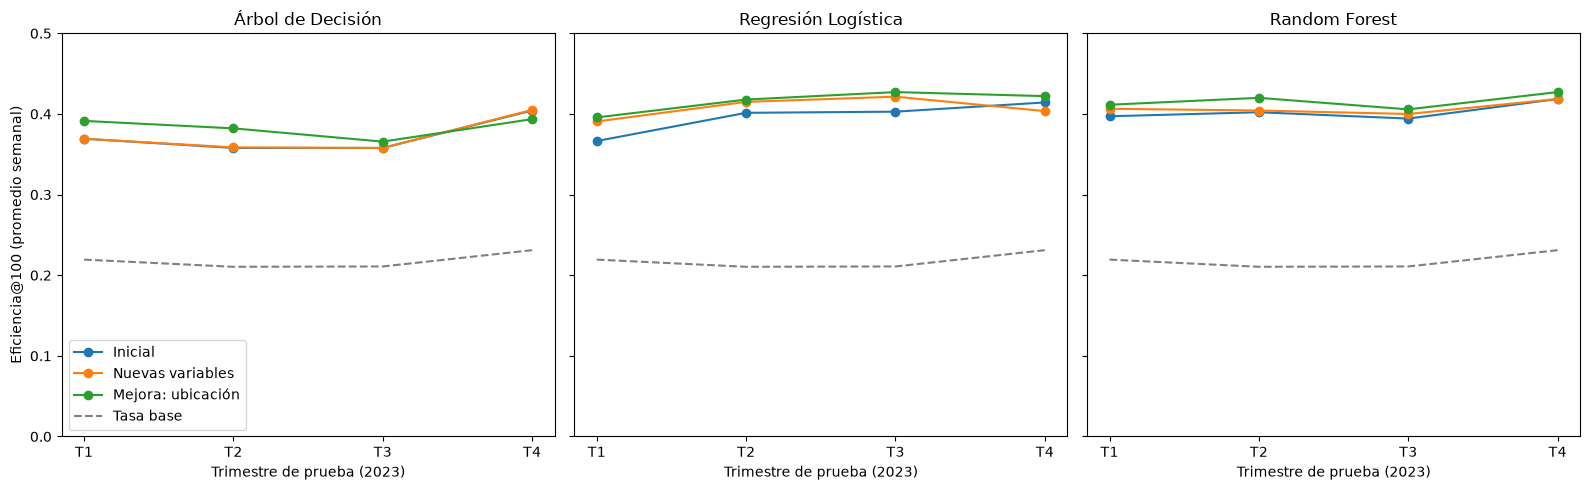

In [27]:
orden_impl   = ['Inicial', 'Nuevas variables', 'Mejora: ubicación']
modelos_graf = ['Árbol de Decisión', 'Regresión Logística', 'Random Forest']
splits       = [s['nombre'] for s in splits_temporales]
etiquetas    = ['T1', 'T2', 'T3', 'T4']

# Tasa base de cada trimestre (es la misma para todos los modelos)
tasa_base_tri = (comparativa[comparativa['modelo'] == 'Línea base (Dummy)']
                 .drop_duplicates('split')
                 .set_index('split')
                 .loc[splits, 'tasa_base'])

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, modelo in zip(axes, modelos_graf):
    datos_modelo = comparativa[comparativa['modelo'] == modelo]
    for impl in orden_impl:
        datos_impl = datos_modelo[datos_modelo['implementacion'] == impl].set_index('split').loc[splits]
        ax.plot(etiquetas, datos_impl['eficiencia@100'], marker='o', label=impl)
    ax.plot(etiquetas, tasa_base_tri.values, linestyle='--', color='gray', label='Tasa base')
    ax.set_title(modelo)
    ax.set_xlabel('Trimestre de prueba (2023)')
    ax.set_ylim(0, 0.5)

axes[0].set_ylabel('Eficiencia@100 (promedio semanal)')
axes[0].legend()
plt.tight_layout()
plt.show()

Para ver los cambios según el número de verificaciones, calculamos la eficiencia y cobertura promedio semanal para distintos valores de k (25-500) para ver qué pasaría si el C5 pudiera verificar más o menos reportes que los 100 actuales. 

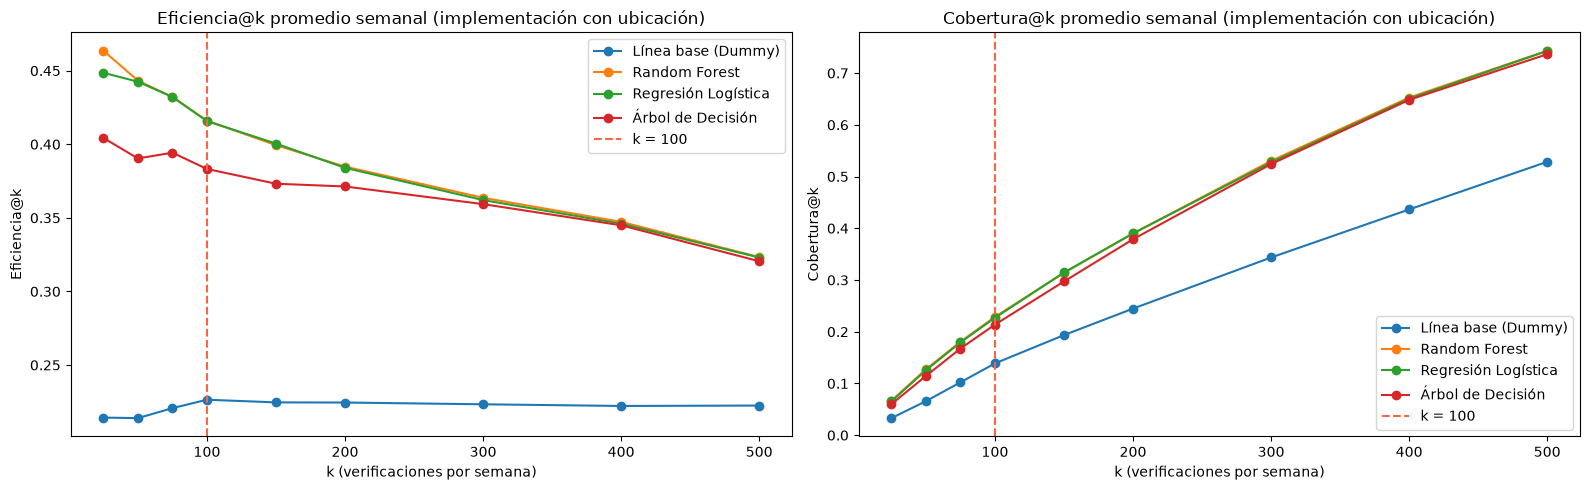

In [28]:
ks = [25, 50, 75, 100, 150, 200, 300, 400, 500]

filas_k = []
for k in ks:
    for (modelo, split, semana), grupo in scores_mejora.groupby(['modelo', 'split', 'semana']):
        tb, ef, cob = metricas_semana(grupo, k=k)
        filas_k.append({'k': k, 'modelo': modelo, 'eficiencia': ef, 'cobertura': cob})

# Promedio semanal para cada k y modelo
curva_k = pd.DataFrame(filas_k).groupby(['k', 'modelo'])[['eficiencia', 'cobertura']].mean().reset_index()

# Gráficas
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for modelo in curva_k['modelo'].unique():
    datos_modelo = curva_k[curva_k['modelo'] == modelo]
    axes[0].plot(datos_modelo['k'], datos_modelo['eficiencia'], marker='o', label=modelo)
    axes[1].plot(datos_modelo['k'], datos_modelo['cobertura'], marker='o', label=modelo)

for ax in axes:
    ax.axvline(100, color='tomato', linestyle='--', label='k = 100')
    ax.set_xlabel('k (verificaciones por semana)')
    ax.legend()

axes[0].set_title('Eficiencia@k promedio semanal (implementación con ubicación)')
axes[0].set_ylabel('Eficiencia@k')
axes[1].set_title('Cobertura@k promedio semanal (implementación con ubicación)')
axes[1].set_ylabel('Cobertura@k')

plt.tight_layout()
plt.show()


### A4.Interpretación

1. ¿Cuánto mejoran o empeoran los modelos respecto de la tasa base y de la implementación inicial?

2. ¿Qué variables o modificaciones tuvieron mayor efecto? ¿Se mantiene el desempeño entre trimestres?

3. ¿Qué modelo recomiendan y cuáles son las limitaciones de la evaluación retrospectiva?